# Emotion Classifier — RAF-DB (EfficientNetB0 · TensorFlow/Keras)
## Kelas: `angry`, `sad`, `fear`, `happy`
## Arsitektur: EfficientNetB0 (TF/Keras) + Optuna + TTA



##  Cell 1 — Install Dependensi
Menginstal library tambahan yang dibutuhkan: **Optuna** (pencarian hyperparameter otomatis), **OpenCV** (pemrosesan gambar / CLAHE), dan **Scikit-learn** (metrik evaluasi).

In [1]:
!pip install -q optuna opencv-python-headless scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 14.9 MB/s eta 0:00:00


##  Cell 2 — Download & Ekstrak Dataset
Mengunduh dataset **Balanced RAF-DB (75×75)** dari Google Drive menggunakan `gdown`, lalu mengekstraknya ke direktori `/content/`. Jika file sudah ada, langkah unduh dilewati.

In [2]:
import os, zipfile

FILE_ID    = '1BqEL2OPTC01uhNzMkuCvwSJTmjVtGfzM'
ZIP_PATH   = '/content/Balanced RAF-DB Dataset (75x75).zip'
EXTRACT_TO = '/content/'

if not os.path.exists(ZIP_PATH):
    print('Mendownload dataset dari Google Drive...')
    !pip install -q gdown
    import gdown
    gdown.download(f'https://drive.google.com/uc?id={FILE_ID}', ZIP_PATH, quiet=False)
    print('Download selesai.')
else:
    print(f'File sudah ada: {ZIP_PATH}')

print(f'Mengekstrak: {ZIP_PATH}')
with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(EXTRACT_TO)

print('\n Ekstraksi selesai. Isi /content/:')
for entry in sorted(os.listdir('/content/')):
    full = os.path.join('/content', entry)
    if os.path.isdir(full):
        subs = sorted(os.listdir(full))[:10]
        print(f'{entry}/ → {subs}')


Mendownload dataset dari Google Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1BqEL2OPTC01uhNzMkuCvwSJTmjVtGfzM
From (redirected): https://drive.google.com/uc?id=1BqEL2OPTC01uhNzMkuCvwSJTmjVtGfzM&confirm=t&uuid=104fb46a-4d15-47b0-b71f-8d27845d89f1
To: /content/Balanced RAF-DB Dataset (75x75).zip
100%|██████████| 130M/130M [00:01<00:00, 78.2MB/s]


Download selesai.
Mengekstrak: /content/Balanced RAF-DB Dataset (75x75).zip

 Ekstraksi selesai. Isi /content/:
.config/ → ['.last_opt_in_prompt.yaml', '.last_survey_prompt.yaml', '.last_update_check.json', 'active_config', 'config_sentinel', 'configurations', 'default_configs.db', 'gce', 'hidden_gcloud_config_universe_descriptor_data_cache_configs.db', 'logs']
sample_data/ → ['README.md', 'anscombe.json', 'california_housing_test.csv', 'california_housing_train.csv', 'mnist_test.csv', 'mnist_train_small.csv']
test/ → ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
train/ → ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
val/ → ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


##  Cell 3 — Konfigurasi Global
Mendefinisikan seluruh **konstanta dan parameter proyek** dalam satu tempat:
- Kelas emosi: `angry`, `sad`, `fear`, `happy`
- Ukuran input model: **224×224** (standar EfficientNetB0)
- Pembagian data: **60% train / 20% val / 20% test**
- Parameter Optuna dan training akhir
- Path penyimpanan model terbaik

In [42]:
import os, glob, random
import numpy as np

DATASET_ROOT = '/content'
CLASSES      = ['angry', 'sad', 'fear', 'happy']
NUM_CLASSES  = len(CLASSES)

IMG_SIZE = 224

SEED         = 42
BATCH_SIZE   = 32
NUM_WORKERS  = 2

TRAIN_PER_CLASS = 2000
VAL_PER_CLASS   = 250
TEST_PER_CLASS  = 250

N_TRIALS      = 10
OPTUNA_EPOCHS = 10

FINAL_EPOCHS  = 10
PATIENCE      = 8

BEST_MODEL_PATH = '/content/best_model_efficientnet_tf.keras'
SAVE_PATH       = '/content/emotion_efficientnet_tf.keras'

random.seed(SEED)
np.random.seed(SEED)

print(f'   Config loaded')
print(f'   IMG_SIZE={IMG_SIZE} | BATCH_SIZE={BATCH_SIZE}')
print(f'   Split: {TRAIN_PER_CLASS}/kelas train | {VAL_PER_CLASS}/kelas val | {TEST_PER_CLASS}/kelas test')
print(f'   Total: {(TRAIN_PER_CLASS+VAL_PER_CLASS+TEST_PER_CLASS)*NUM_CLASSES:,} gambar')


   Config loaded
   IMG_SIZE=224 | BATCH_SIZE=32
   Split: 2000/kelas train | 250/kelas val | 250/kelas test
   Total: 10,000 gambar


##  Cell 4 — Import Library & Verifikasi GPU
Mengimpor semua library yang diperlukan (TensorFlow, OpenCV, Optuna, Matplotlib, dll.) dan **memverifikasi bahwa GPU (T4) aktif** di Google Colab. Training akan batal jika GPU tidak terdeteksi.

In [18]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import optuna
import warnings
from collections import Counter
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

tf.random.set_seed(SEED)


gpus = tf.config.list_physical_devices('GPU')
assert len(gpus) > 0, (
    '   GPU tidak terdeteksi!\n'
    '   Aktifkan via: Runtime > Change runtime type > T4 GPU'
)

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

print(f'   TensorFlow: {tf.__version__}')
print(f'   GPU tersedia: {[g.name for g in gpus]}')


   TensorFlow: 2.20.0
   GPU tersedia: ['/physical_device:GPU:0']


##  Cell 5 — Scan & Sampling Dataset
Membaca daftar path gambar dari folder `train/`, `val/`, dan `test/`, lalu **mengambil sampel acak** sejumlah yang ditentukan per kelas (TRAIN=1500, VAL=500, TEST=500). Memastikan semua kelas tersedia.

In [19]:
def collect_images_from_split(root, split_name, classes, per_class, seed=42):
    """
    Ambil per_class gambar acak dari root/<split_name>/<cls>/ untuk setiap kelas.
    Return: (list path, list label_int, dict ketersediaan)
    """
    split_dir = os.path.join(root, split_name)
    if not os.path.isdir(split_dir):
        raise FileNotFoundError(f' Folder tidak ditemukan: {split_dir}')

    all_paths, all_labels = [], []
    rng          = random.Random(seed)
    availability = {}

    for cls_idx, cls_name in enumerate(classes):
        cls_dir = os.path.join(split_dir, cls_name)
        found   = []
        if os.path.isdir(cls_dir):
            for ext in ('*.jpg', '*.jpeg', '*.png'):
                found.extend(glob.glob(os.path.join(cls_dir, '**', ext), recursive=True))
        found = list(set(found))
        availability[cls_name] = len(found)

        if len(found) < per_class:
            raise ValueError(
                f' {split_name}/{cls_name}: hanya {len(found)} gambar, butuh {per_class}.'
            )

        sampled = rng.sample(found, per_class)
        all_paths.extend(sampled)
        all_labels.extend([cls_idx] * per_class)

    return all_paths, all_labels, availability


print(f' Scanning dataset di: {DATASET_ROOT}')

paths_train, labels_train, avail_train = collect_images_from_split(
    DATASET_ROOT, 'train', CLASSES, TRAIN_PER_CLASS, SEED)
print(f'    train/: {len(CLASSES)} kelas ditemukan')

paths_val, labels_val, avail_val = collect_images_from_split(
    DATASET_ROOT, 'val', CLASSES, VAL_PER_CLASS, SEED)
print(f'    val/:   {len(CLASSES)} kelas ditemukan')

paths_test, labels_test, avail_test = collect_images_from_split(
    DATASET_ROOT, 'test', CLASSES, TEST_PER_CLASS, SEED)
print(f'    test/:  {len(CLASSES)} kelas ditemukan')

print()
for cls in CLASSES:
    print(f' [{cls:>8}] train={avail_train[cls]} → ambil={TRAIN_PER_CLASS}'
          f' | val={avail_val[cls]} → ambil={VAL_PER_CLASS}'
          f' | test={avail_test[cls]} → ambil={TEST_PER_CLASS}')

total = len(paths_train) + len(paths_val) + len(paths_test)
print(f'\n Total: Train={len(paths_train)} | Val={len(paths_val)} | Test={len(paths_test)} | Grand Total={total}')


 Scanning dataset di: /content
    train/: 4 kelas ditemukan
    val/:   4 kelas ditemukan
    test/:  4 kelas ditemukan

 [   angry] train=4289 → ambil=2000 | val=1072 → ambil=250 | test=595 → ambil=250
 [     sad] train=4289 → ambil=2000 | val=1072 → ambil=250 | test=595 → ambil=250
 [    fear] train=4289 → ambil=2000 | val=1072 → ambil=250 | test=595 → ambil=250
 [   happy] train=4289 → ambil=2000 | val=1072 → ambil=250 | test=595 → ambil=250

 Total: Train=8000 | Val=1000 | Test=1000 | Grand Total=10000


##  Cell 6 — Verifikasi Split Dataset
Menampilkan **ringkasan distribusi data** untuk memastikan setiap kelas memiliki jumlah gambar yang seimbang di setiap split (train/val/test).

In [15]:
total = len(paths_train) + len(paths_val) + len(paths_test)
print('Verifikasi split:')
print(f'   Train : {len(paths_train):>5} ({len(paths_train)/total*100:.0f}%)')
print(f'   Val   : {len(paths_val):>5} ({len(paths_val)/total*100:.0f}%)')
print(f'   Test  : {len(paths_test):>5} ({len(paths_test)/total*100:.0f}%)')
print(f'\n   Distribusi train : { {CLASSES[k]: v for k,v in Counter(labels_train).items()} }')
print(f'   Distribusi val   : { {CLASSES[k]: v for k,v in Counter(labels_val).items()} }')
print(f'   Distribusi test  : { {CLASSES[k]: v for k,v in Counter(labels_test).items()} }')
print('\n Semua kelas seimbang') if len(set(Counter(labels_train).values())) == 1 \
    else print('Distribusi tidak seimbang!')


Verifikasi split:
   Train :  7000 (70%)
   Val   :  2000 (20%)
   Test  :  1000 (10%)

   Distribusi train : {'angry': 1750, 'sad': 1750, 'fear': 1750, 'happy': 1750}
   Distribusi val   : {'angry': 500, 'sad': 500, 'fear': 500, 'happy': 500}
   Distribusi test  : {'angry': 250, 'sad': 250, 'fear': 250, 'happy': 250}

 Semua kelas seimbang


##  Cell 7 — Preprocessing CLAHE + Pipeline tf.data
Membangun **pipeline data TensorFlow** yang efisien dengan tiga tahap:
1. **CLAHE** (Contrast Limited Adaptive Histogram Equalization) diterapkan pada kanal `L` di ruang warna Lab — meningkatkan kontras tanpa mengubah warna.
2. **Augmentasi** (hanya untuk training): flip horizontal, variasi kecerahan/kontras, random crop, random zoom.
3. **Normalisasi** sesuai standar EfficientNetB0 (ImageNet mean/std).

Pipeline menggunakan `prefetch` + `AUTOTUNE` untuk kecepatan maksimal.

In [20]:

def apply_clahe_numpy(path_bytes):
    path = path_bytes.numpy().decode('utf-8')
    bgr  = cv2.imread(path)
    if bgr is None:
        bgr = np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    lab    = cv2.cvtColor(bgr, cv2.COLOR_BGR2Lab)
    l, a, b = cv2.split(lab)
    clahe  = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
    l_eq   = clahe.apply(l)
    lab_eq = cv2.merge([l_eq, a, b])
    rgb    = cv2.cvtColor(lab_eq, cv2.COLOR_Lab2RGB)
    return rgb.astype(np.uint8)


def load_and_clahe(path, label):
    img = tf.py_function(
        func=apply_clahe_numpy,
        inp=[path],
        Tout=tf.uint8
    )
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32)
    return img, label


def augment_train(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, max_delta=0.35)
    img = tf.image.random_contrast(img, lower=0.65, upper=1.35)
    img = tf.image.resize_with_crop_or_pad(img, IMG_SIZE + 20, IMG_SIZE + 20)
    img = tf.image.random_crop(img, size=[IMG_SIZE, IMG_SIZE, 3])
    scale = tf.random.uniform((), 0.90, 1.10)
    new_h = tf.cast(tf.cast(IMG_SIZE, tf.float32) * scale, tf.int32)
    new_w = new_h
    img = tf.image.resize(img, [new_h, new_w])
    img = tf.image.resize_with_crop_or_pad(img, IMG_SIZE, IMG_SIZE)
    return img, label


def preprocess_efficientnet(img, label):
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label


AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(paths, labels, is_training=False, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if is_training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)

    N_PARALLEL_IO = min(4, os.cpu_count() or 1)
    ds = ds.map(load_and_clahe, num_parallel_calls=N_PARALLEL_IO)

    if is_training:
        ds = ds.map(augment_train, num_parallel_calls=AUTOTUNE)
    ds = ds.map(preprocess_efficientnet, num_parallel_calls=AUTOTUNE)

    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    return ds


train_ds = make_dataset(paths_train, labels_train, is_training=True)
val_ds   = make_dataset(paths_val,   labels_val,   is_training=False)
test_ds  = make_dataset(paths_test,  labels_test,  is_training=False)

print(f' tf.data Pipelines siap')
print(f'   train_ds : {len(paths_train)} sampel | CLAHE + augmentasi + prefetch')
print(f'   val_ds   : {len(paths_val)} sampel  | CLAHE + prefetch')
print(f'   test_ds  : {len(paths_test)} sampel  | CLAHE + prefetch')


 tf.data Pipelines siap
   train_ds : 8000 sampel | CLAHE + augmentasi + prefetch
   val_ds   : 1000 sampel  | CLAHE + prefetch
   test_ds  : 1000 sampel  | CLAHE + prefetch


##  Cell 8 — Visualisasi Perbandingan: Sebelum vs Sesudah Pipeline
Menampilkan **4 sampel gambar** (1 per kelas emosi) secara berdampingan:
- **Kolom Kiri**: Gambar asli dari dataset
- **Kolom Kanan**: Gambar setelah **full pipeline training** (CLAHE + augmentasi: random flip, brightness, contrast, crop, scale)

> Kolom kanan bersifat **acak** — hasilnya berbeda setiap cell dijalankan ulang.

In [ ]:
import matplotlib.patches as mpatches
import tensorflow as tf
import numpy as np
import cv2
import random

N_SAMPLES = 4
SEED_VIS  = 42
random.seed(SEED_VIS)

# ── Pilih 1 gambar per kelas ──────────────────────────────────
sample_paths  = []
sample_labels = []
used_classes  = set()

shuffled = list(zip(paths_train, labels_train))
random.shuffle(shuffled)

for p, lbl in shuffled:
    if lbl not in used_classes:
        sample_paths.append(p)
        sample_labels.append(lbl)
        used_classes.add(lbl)
    if len(sample_paths) == N_SAMPLES:
        break

while len(sample_paths) < N_SAMPLES:
    p, lbl = random.choice(list(zip(paths_train, labels_train)))
    sample_paths.append(p)
    sample_labels.append(lbl)


# ── Fungsi helper ─────────────────────────────────────────────
def read_original_rgb(path):
    """Gambar asli (BGR -> RGB), tanpa processing apapun."""
    bgr = cv2.imread(path)
    if bgr is None:
        return np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def apply_full_pipeline(path):
    """CLAHE (Lab-space) + augmentasi training, identik dengan make_dataset()."""
    # 1. CLAHE
    bgr = cv2.imread(path)
    if bgr is None:
        return np.zeros((IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
    lab     = cv2.cvtColor(bgr, cv2.COLOR_BGR2Lab)
    l, a, b = cv2.split(lab)
    clahe   = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
    l_eq    = clahe.apply(l)
    lab_eq  = cv2.merge([l_eq, a, b])
    rgb     = cv2.cvtColor(lab_eq, cv2.COLOR_Lab2RGB)

    # 2. Resize awal (sama dengan load_and_clahe)
    img = tf.image.resize(rgb.astype(np.float32), [IMG_SIZE, IMG_SIZE])

    # 3. Augmentasi (sama persis dengan augment_train)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_brightness(img, max_delta=0.35)
    img = tf.image.random_contrast(img, lower=0.65, upper=1.35)
    img = tf.image.resize_with_crop_or_pad(img, IMG_SIZE + 20, IMG_SIZE + 20)
    img = tf.image.random_crop(img, size=[IMG_SIZE, IMG_SIZE, 3])
    scale = tf.random.uniform((), 0.90, 1.10)
    new_hw = tf.cast(tf.cast(IMG_SIZE, tf.float32) * scale, tf.int32)
    img = tf.image.resize(img, [new_hw, new_hw])
    img = tf.image.resize_with_crop_or_pad(img, IMG_SIZE, IMG_SIZE)

    img = tf.clip_by_value(img, 0, 255)
    return img.numpy().astype(np.uint8)


# ── Layout: 4 baris x 2 kolom ────────────────────────────────
CLASS_COLORS = {
    'angry': '#f87171',
    'sad'  : '#818cf8',
    'fear' : '#fbbf24',
    'happy': '#4ade80',
}

fig, axes = plt.subplots(
    N_SAMPLES, 2,
    figsize=(8, N_SAMPLES * 2.8),
    gridspec_kw={'wspace': 0.08, 'hspace': 0.45}
)

for row, (path, lbl_idx) in enumerate(zip(sample_paths, sample_labels)):
    class_name = CLASSES[lbl_idx]
    color      = CLASS_COLORS.get(class_name, '#aaaaaa')

    img_orig = read_original_rgb(path)
    img_proc = apply_full_pipeline(path)

    for col, (img, title) in enumerate([
        (img_orig, 'Original  [' + class_name.upper() + ']'),
        (img_proc, 'CLAHE + Augmentasi  [' + class_name.upper() + ']'),
    ]):
        ax = axes[row, col]
        ax.imshow(img)
        ax.set_title(title, fontsize=9, fontweight='bold', color=color, pad=4)
        ax.axis('off')
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(2)
            spine.set_visible(True)

# ── Header kolom ─────────────────────────────────────────────
fig.text(0.27, 0.995, 'Gambar Asli (Original)',
         ha='center', va='top', fontsize=11, fontweight='bold', color='#374151')
fig.text(0.73, 0.995, 'Setelah CLAHE + Augmentasi',
         ha='center', va='top', fontsize=11, fontweight='bold', color='#374151')

# ── Garis pemisah vertikal ───────────────────────────────────
fig.add_artist(plt.Line2D(
    [0.515, 0.515], [0.01, 0.99],
    transform=fig.transFigure,
    color='#d1d5db', linewidth=1.2, linestyle='--'
))

# ── Judul utama ───────────────────────────────────────────────
fig.suptitle(
    'Perbandingan Gambar Sebelum vs Sesudah Pipeline Preprocessing  |  4 Sampel (1 per Kelas)',
    fontsize=11, fontweight='bold', y=1.03, color='#111827'
)

# ── Legend kelas ─────────────────────────────────────────────
legend_patches = [
    mpatches.Patch(color=c, label=cls.capitalize())
    for cls, c in CLASS_COLORS.items()
]
fig.legend(
    handles=legend_patches,
    loc='lower center', ncol=4,
    fontsize=8, framealpha=0.7,
    bbox_to_anchor=(0.5, -0.01)
)

plt.tight_layout()
plt.show()

print('Sample yang ditampilkan:')
for i, (p, lbl) in enumerate(zip(sample_paths, sample_labels), 1):
    fname = p.split('/')[-1]
    print('  [' + str(i) + '] ' + CLASSES[lbl].upper().ljust(6) + ' -- ' + fname)
print()
print('Catatan: Kolom kanan bersifat RANDOM (augmentasi acak) -- hasil berbeda setiap run.')


##  Cell 9 — Arsitektur Model (EfficientNetB0)
Membangun fungsi `build_model()` yang membuat model dengan arsitektur:
- **Backbone**: EfficientNetB0 pre-trained dari ImageNet (Transfer Learning)
- **Head**: Global Average Pooling → Dropout → Dense(NUM_CLASSES, softmax)
- Parameter `dropout` dan `trainable_backbone` dapat dikonfigurasi untuk Optuna.

In [22]:
def build_model(dropout: float = 0.3, trainable_backbone: bool = False):
    backbone = tf.keras.applications.EfficientNetB0(
        include_top    = False,
        weights        = 'imagenet',
        input_shape    = (IMG_SIZE, IMG_SIZE, 3),
        pooling        = None,
    )
    backbone.trainable = trainable_backbone

    inputs  = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x       = backbone(inputs, training=trainable_backbone)
    x       = tf.keras.layers.GlobalAveragePooling2D()(x)
    x       = tf.keras.layers.Dropout(dropout)(x)
    x       = tf.keras.layers.Dense(256, activation='relu',
                                    kernel_regularizer=tf.keras.regularizers.l2(1e-4))(x)
    x       = tf.keras.layers.Dropout(dropout * 0.7)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs)
    return model

_m = build_model()
_x = tf.random.normal([2, IMG_SIZE, IMG_SIZE, 3])
_y = _m(_x, training=False)
assert _y.shape == (2, NUM_CLASSES), f'Shape output salah: {_y.shape}'

trainable_params = np.sum([np.prod(v.shape) for v in _m.trainable_variables])
total_params     = np.sum([np.prod(v.shape) for v in _m.variables])
print(f'   EfficientNetB0 Model OK')
print(f'   Output shape    : {list(_y.shape)}')
print(f'   Classifier head : GAP → Dropout({0.3}) → Dense(256) → Dropout({0.21:.2f}) → Dense({NUM_CLASSES})')
print(f'   Trainable params: {trainable_params:,} / {total_params:,} ({trainable_params/total_params*100:.1f}%)')
del _m, _x, _y


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
   EfficientNetB0 Model OK
   Output shape    : [2, 4]
   Classifier head : GAP → Dropout(0.3) → Dense(256) → Dropout(0.21) → Dense(4)
   Trainable params: 328,964 / 4,378,557.0 (7.5%)


## Cell 10 — Fungsi Loss (Label Smoothing) / Optuna Hyperparameter Search
Menjalankan **pencarian hyperparameter otomatis** menggunakan Optuna selama N_TRIALS percobaan. Parameter yang dioptimalkan:
- `lr` (learning rate): rentang `1e-4` hingga `1e-2`
- `dropout`: rentang `0.1` hingga `0.5`
- `weight_decay`: rentang `1e-5` hingga `1e-2`
- `label_smoothing`: rentang `0.0` hingga `0.2`

Setiap trial melatih model selama OPTUNA_EPOCHS epoch. Parameter terbaik dipilih berdasarkan **val_accuracy** tertinggi.

In [23]:
import gc

def make_label_smoothing_loss(label_smoothing: float, num_classes: int):
    """
    Custom loss dengan label smoothing yang kompatibel dengan sparse integer labels.
    Mengonversi label integer → one-hot → apply smoothing → cross-entropy.
    """
    def loss_fn(y_true, y_pred):
        y_true_oh = tf.one_hot(tf.cast(y_true, tf.int32), num_classes)
        y_true_smooth = y_true_oh * (1.0 - label_smoothing) + \
                        (label_smoothing / num_classes)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0)
        return -tf.reduce_mean(tf.reduce_sum(y_true_smooth * tf.math.log(y_pred), axis=-1))
    return loss_fn


def objective(trial: optuna.Trial):
    """
    Fungsi objektif Optuna.
    Setiap trial: bangun model baru → latih OPTUNA_EPOCHS epoch → return best val_accuracy.
    """
    lr              = trial.suggest_float('lr', 5e-5, 3e-3, log=True)
    weight_decay    = trial.suggest_float('weight_decay', 1e-5, 5e-3, log=True)
    dropout         = trial.suggest_float('dropout', 0.2, 0.5)
    label_smoothing = trial.suggest_float('label_smoothing', 0.01, 0.10)

    model     = build_model(dropout=dropout, trainable_backbone=False)
    optimizer = tf.keras.optimizers.AdamW(learning_rate=lr, weight_decay=weight_decay)
    loss_fn   = make_label_smoothing_loss(label_smoothing, NUM_CLASSES)

    model.compile(
        optimizer = optimizer,
        loss      = loss_fn,
        metrics   = ['accuracy'],
    )

    best_val_acc = 0.0
    for epoch in range(OPTUNA_EPOCHS):
        history_trial = model.fit(
            train_ds,
            validation_data = val_ds,
            epochs          = 1,
            verbose         = 0,
        )
        val_acc = history_trial.history['val_accuracy'][-1]
        best_val_acc = max(best_val_acc, val_acc)

        trial.report(val_acc, epoch)
        if trial.should_prune():
            del model
            gc.collect()
            tf.keras.backend.clear_session()
            raise optuna.exceptions.TrialPruned()

    del model
    gc.collect()
    tf.keras.backend.clear_session()
    return best_val_acc


print(f' Optuna search ({N_TRIALS} trial × {OPTUNA_EPOCHS} epoch)...')
study = optuna.create_study(
    direction = 'maximize',
    pruner    = optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=4),
    sampler   = optuna.samplers.TPESampler(seed=SEED),
)
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

best_params = study.best_params
print(f'\n Best Val Acc : {study.best_value:.4f}')
print(f'   Best Params  : {best_params}')

 Optuna search (10 trial × 10 epoch)...


  0%|          | 0/10 [00:00<?, ?it/s]


 Best Val Acc : 0.7600
   Best Params  : {'lr': 0.0005859268690985102, 'weight_decay': 0.000814829321010529, 'dropout': 0.20617534828874073, 'label_smoothing': 0.0972918866945795}


## Cell 11 — Visualisasi Hasil Optuna
Menampilkan dua grafik:
1. **Trial Values** — progres akurasi validasi di setiap trial Optuna.
2. **Hyperparameter Importance** — seberapa besar pengaruh setiap parameter terhadap hasil.

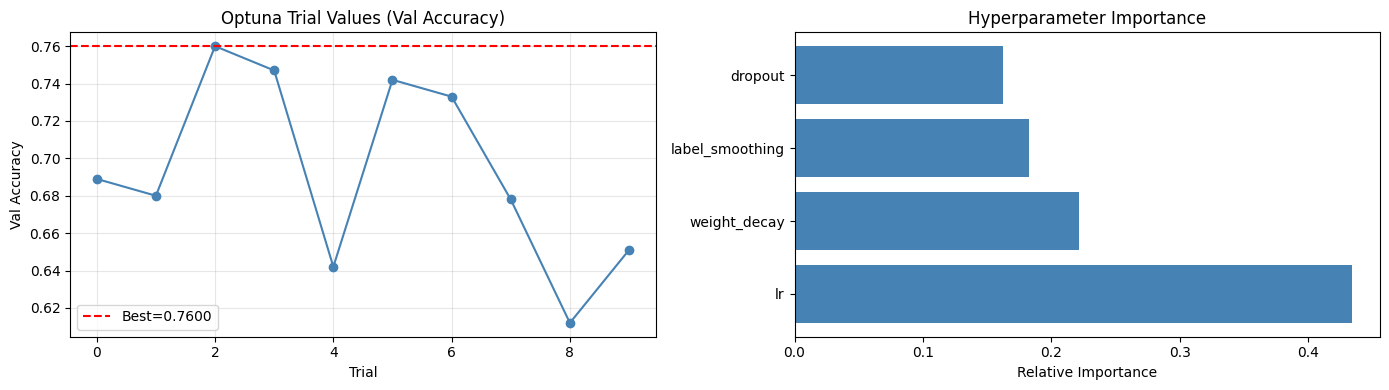

Selesai=5 | Dipangkas=5


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

vals = [t.value for t in study.trials if t.value is not None]
axes[0].plot(vals, marker='o', color='steelblue')
axes[0].axhline(study.best_value, color='red', ls='--',
                label=f'Best={study.best_value:.4f}')
axes[0].set_title('Optuna Trial Values (Val Accuracy)')
axes[0].set_xlabel('Trial')
axes[0].set_ylabel('Val Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

try:
    importance = optuna.importance.get_param_importances(study)
    axes[1].barh(list(importance.keys()), list(importance.values()), color='steelblue')
    axes[1].set_title('Hyperparameter Importance')
    axes[1].set_xlabel('Relative Importance')
except Exception:
    axes[1].text(0.5, 0.5, 'Tidak cukup trial untuk importance', ha='center', va='center')

plt.tight_layout()
plt.show()

pruned  = len([t for t in study.trials if t.state == optuna.trial.TrialState.PRUNED])
done    = len([t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE])
print(f'Selesai={done} | Dipangkas={pruned}')


## Cell 12 — Final Training (Single Stage)
Melatih model **menggunakan hyperparameter terbaik** dari Optuna:
- Backbone **trainable** dari awal (tidak dibekukan)
- Optimizer **AdamW** dengan **Cosine Decay** learning rate schedule
- **Callbacks**: EarlyStopping (patience=12) + ModelCheckpoint (simpan model terbaik)

Model terbaik disimpan ke `best_model_efficientnet_tf.keras`.

In [43]:
import gc
tf.keras.backend.clear_session()
gc.collect()

model = build_model(dropout=best_params['dropout'], trainable_backbone=True)

total_steps = FINAL_EPOCHS * (len(paths_train) // BATCH_SIZE)
lr_schedule = tf.keras.optimizers.schedules.CosineDecay(
    initial_learning_rate = best_params['lr'],
    decay_steps           = total_steps,
    alpha                 = 0.01,
)

optimizer = tf.keras.optimizers.AdamW(
    learning_rate = lr_schedule,
    weight_decay  = best_params['weight_decay'],
)
model.compile(
    optimizer = optimizer,
    loss      = make_label_smoothing_loss(best_params['label_smoothing'], NUM_CLASSES),
    metrics   = ['accuracy'],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor   = 'val_accuracy',
        patience  = PATIENCE,
        restore_best_weights = True,
        verbose   = 1,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath          = BEST_MODEL_PATH,
        monitor           = 'val_accuracy',
        save_best_only    = True,
        save_weights_only = False,
        verbose           = 1,
    ),
]

print(f'Final Training — Single Stage (EfficientNetB0 TF)')
print(f'label_smoothing={best_params["label_smoothing"]:.3f} | dropout={best_params["dropout"]:.3f}')
print(f'lr={best_params["lr"]:.2e} | wd={best_params["weight_decay"]:.2e}')
print(f'trainable_backbone=True (seluruh backbone) | epochs={FINAL_EPOCHS}')
print()

hist = model.fit(
    train_ds,
    validation_data = val_ds,
    epochs          = FINAL_EPOCHS,
    callbacks       = callbacks,
    verbose         = 1,
)

history_all = {
    'train_loss': hist.history['loss'],
    'train_acc': hist.history['accuracy'],
    'val_loss': hist.history['val_loss'],
    'val_acc': hist.history['val_accuracy'],
}

best_val_acc = max(history_all['val_acc'])
print(f'\n Best Val Accuracy: {best_val_acc*100:.2f}%')
print(f'   Best model disimpan di: {BEST_MODEL_PATH}')
print(f'   Final Train Loss: {history_all["train_loss"][-1]:.4f}')
print(f'   Final Val Loss:   {history_all["val_loss"][-1]:.4f}')


Final Training — Single Stage (EfficientNetB0 TF)
label_smoothing=0.097 | dropout=0.206
lr=5.86e-04 | wd=8.15e-04
trainable_backbone=True (seluruh backbone) | epochs=10

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 191ms/step - accuracy: 0.6146 - loss: 1.0612
Epoch 1: val_accuracy improved from None to 0.78000, saving model to /content/best_model_efficientnet_tf.keras

Epoch 1: finished saving model to /content/best_model_efficientnet_tf.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 145s 252ms/step - accuracy: 0.7415 - loss: 0.8734 - val_accuracy: 0.7800 - val_loss: 0.8013
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.9010 - loss: 0.5998
Epoch 2: val_accuracy improved from 0.78000 to 0.94200, saving model to /content/best_model_efficientnet_tf.keras

Epoch 2: finished saving model to /content/best_model_efficientnet_tf.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 51s 205ms/step - accuracy: 0.9072 - loss: 0.5886 - val_accuracy: 0.9420 - val_loss: 0.5144
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━

## Cell 13 — Plot History Training
Memvisualisasikan **kurva akurasi dan loss** selama proses training (train vs. validation) untuk mendeteksi overfitting atau underfitting.

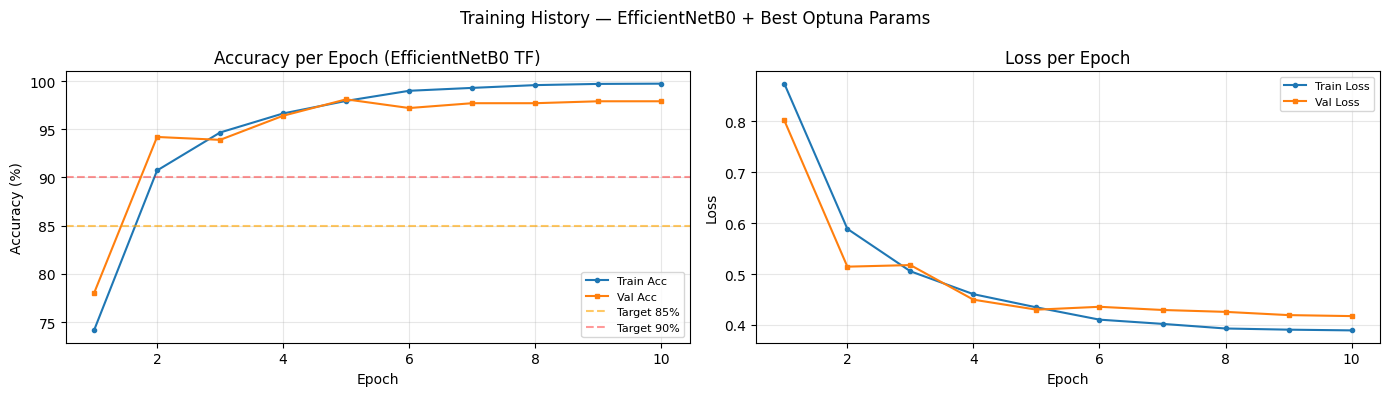

Gap Train-Val : 1.83% → Tidak overfitting
Best Val Acc  : 98.10%


In [44]:
ep = range(1, len(history_all['train_acc']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(ep, [a*100 for a in history_all['train_acc']], label='Train Acc', marker='o', ms=3)
axes[0].plot(ep, [a*100 for a in history_all['val_acc']],   label='Val Acc',   marker='s', ms=3)
axes[0].axhline(85, color='orange', ls='--', alpha=0.6, label='Target 85%')
axes[0].axhline(90, color='red',    ls='--', alpha=0.4, label='Target 90%')
axes[0].set_title('Accuracy per Epoch (EfficientNetB0 TF)')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy (%)')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

axes[1].plot(ep, history_all['train_loss'], label='Train Loss', marker='o', ms=3)
axes[1].plot(ep, history_all['val_loss'],   label='Val Loss',   marker='s', ms=3)
axes[1].set_title('Loss per Epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend(fontsize=8)
axes[1].grid(True, alpha=0.3)

plt.suptitle('Training History — EfficientNetB0 + Best Optuna Params', fontsize=12)
plt.tight_layout()
plt.show()

gap    = (history_all['train_acc'][-1] - history_all['val_acc'][-1]) * 100
status = 'Tidak overfitting' if gap < 7 else 'Sedikit overfitting' if gap < 15 else 'Overfitting'
print(f'Gap Train-Val : {gap:.2f}% → {status}')
print(f'Best Val Acc  : {best_val_acc*100:.2f}%')

## Cell 14 — Evaluasi dengan TTA (Test Time Augmentation)
Melakukan **evaluasi final** pada test set menggunakan **Test Time Augmentation (TTA)**:
- Setiap gambar diprediksi **5 kali** dengan augmentasi ringan yang berbeda
- Hasil probabilitas dari 5 prediksi **dirata-ratakan** untuk keputusan akhir
- Menghasilkan metrik: **Accuracy, Precision, Recall, F1-score** per kelas

In [45]:
def make_tta_dataset(paths, labels, augment_fn, batch_size=BATCH_SIZE):
    """Buat dataset TTA dengan augmentasi tambahan."""
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_and_clahe,          num_parallel_calls=AUTOTUNE)
    ds = ds.map(augment_fn,              num_parallel_calls=AUTOTUNE)
    ds = ds.map(preprocess_efficientnet, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

def tta_identity(img, label): return img, label
def tta_hflip(img, label):    return tf.image.flip_left_right(img), label
def tta_bright(img, label):   return tf.image.adjust_brightness(img, 0.15), label
def tta_contrast(img, label): return tf.image.adjust_contrast(img, 1.2), label
def tta_crop(img, label):
    img = tf.image.resize_with_crop_or_pad(img, IMG_SIZE + 16, IMG_SIZE + 16)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    return img, label

tta_fns = [tta_identity, tta_hflip, tta_bright, tta_contrast, tta_crop]

print(f'Memuat best model dari: {BEST_MODEL_PATH}')
best_model = build_model(dropout=best_params['dropout'], trainable_backbone=True)
best_model.load_weights(BEST_MODEL_PATH)

best_model.compile(
    optimizer = 'adam',
    loss      = tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics   = ['accuracy'],
)
print('Model dimuat.')

print(f'\n Menjalankan TTA ({len(tta_fns)} variasi)...')
n         = len(paths_test)
tta_probs = np.zeros((n, NUM_CLASSES), dtype=np.float32)

for fn in tta_fns:
    tta_ds     = make_tta_dataset(paths_test, labels_test, fn)
    probs_fold = best_model.predict(tta_ds, verbose=0)
    tta_probs += probs_fold

tta_probs /= len(tta_fns)
tta_preds  = np.argmax(tta_probs, axis=1)
tta_labels = np.array(labels_test)
tta_acc    = np.mean(tta_preds == tta_labels)

base_loss, base_acc = best_model.evaluate(test_ds, verbose=0)
print(f'   Base Test Accuracy : {base_acc*100:.2f}%')
print(f'   TTA  Test Accuracy : {tta_acc*100:.2f}%')
print(f'   Peningkatan TTA    : +{(tta_acc - base_acc)*100:.2f}%')

Memuat best model dari: /content/best_model_efficientnet_tf.keras
Model dimuat.

 Menjalankan TTA (5 variasi)...
   Base Test Accuracy : 96.00%
   TTA  Test Accuracy : 96.40%
   Peningkatan TTA    : +0.40%


## Cell 15 — Classification Report (Laporan Metrik)
Menampilkan **laporan klasifikasi lengkap** dari Scikit-learn:
- **Precision**: Ketepatan prediksi per kelas
- **Recall**: Tingkat deteksi per kelas
- **F1-score**: Rata-rata harmonik precision & recall
- **Support**: Jumlah sampel uji per kelas

In [46]:
from sklearn.metrics import classification_report, precision_recall_fscore_support

print('='*60)
print('HASIL EVALUASI (TTA, Test Set)')
print('='*60)
print(f'  Accuracy : {tta_acc*100:.2f}%')

precision, recall, f1, _ = precision_recall_fscore_support(
    tta_labels, tta_preds, average='macro')
print(f'  F1 Macro  : {f1:.4f}')
print(f'  Precision : {precision:.4f}')
print(f'  Recall    : {recall:.4f}')
print('='*60)
print(classification_report(tta_labels, tta_preds, target_names=CLASSES, digits=4))
print('='*60)

f1_macro   = f1
prec_macro = precision
rec_macro  = recall

HASIL EVALUASI (TTA, Test Set)
  Accuracy : 96.40%
  F1 Macro  : 0.9639
  Precision : 0.9641
  Recall    : 0.9640
              precision    recall  f1-score   support

       angry     0.9504    0.9960    0.9727       250
         sad     0.9555    0.9440    0.9497       250
        fear     0.9920    0.9880    0.9900       250
       happy     0.9587    0.9280    0.9431       250

    accuracy                         0.9640      1000
   macro avg     0.9641    0.9640    0.9639      1000
weighted avg     0.9641    0.9640    0.9639      1000



## Cell 16 — Confusion Matrix
Menampilkan **Confusion Matrix** dari hasil prediksi pada test set — memvisualisasikan berapa banyak gambar yang diklasifikasikan dengan benar dan salah untuk setiap pasangan kelas.

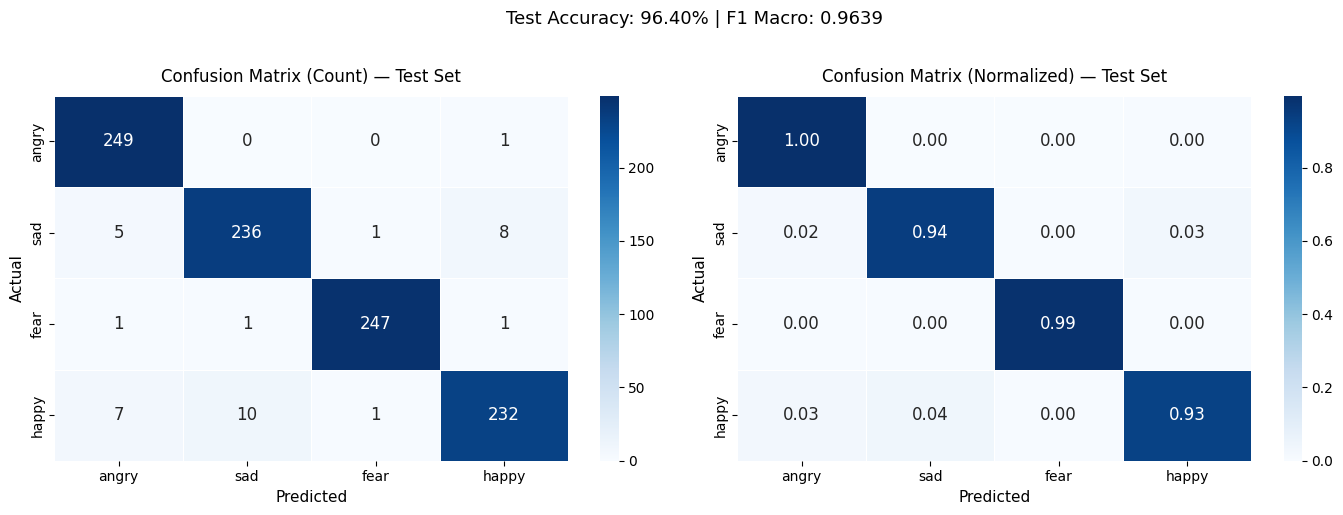

In [47]:
cm      = confusion_matrix(tta_labels, tta_preds)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, title, fmt in zip(
    axes,
    [cm, cm_norm],
    ['Confusion Matrix (Count) — Test Set',
     'Confusion Matrix (Normalized) — Test Set'],
    ['d', '.2f']
):
    sns.heatmap(data, annot=True, fmt=fmt, cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
                annot_kws={'size': 12}, linewidths=0.5)
    ax.set_title(title, fontsize=12, pad=10)
    ax.set_xlabel('Predicted', fontsize=11)
    ax.set_ylabel('Actual', fontsize=11)

plt.suptitle(f'Test Accuracy: {tta_acc*100:.2f}% | F1 Macro: {f1_macro:.4f}',
             fontsize=13, y=1.02)
plt.tight_layout()
plt.show()


## Cell 17 — Visualisasi Sampel Prediksi
Menampilkan **16 gambar sampel** dari test set beserta label aktual dan prediksi model, sehingga kesalahan klasifikasi dapat langsung terlihat secara visual.

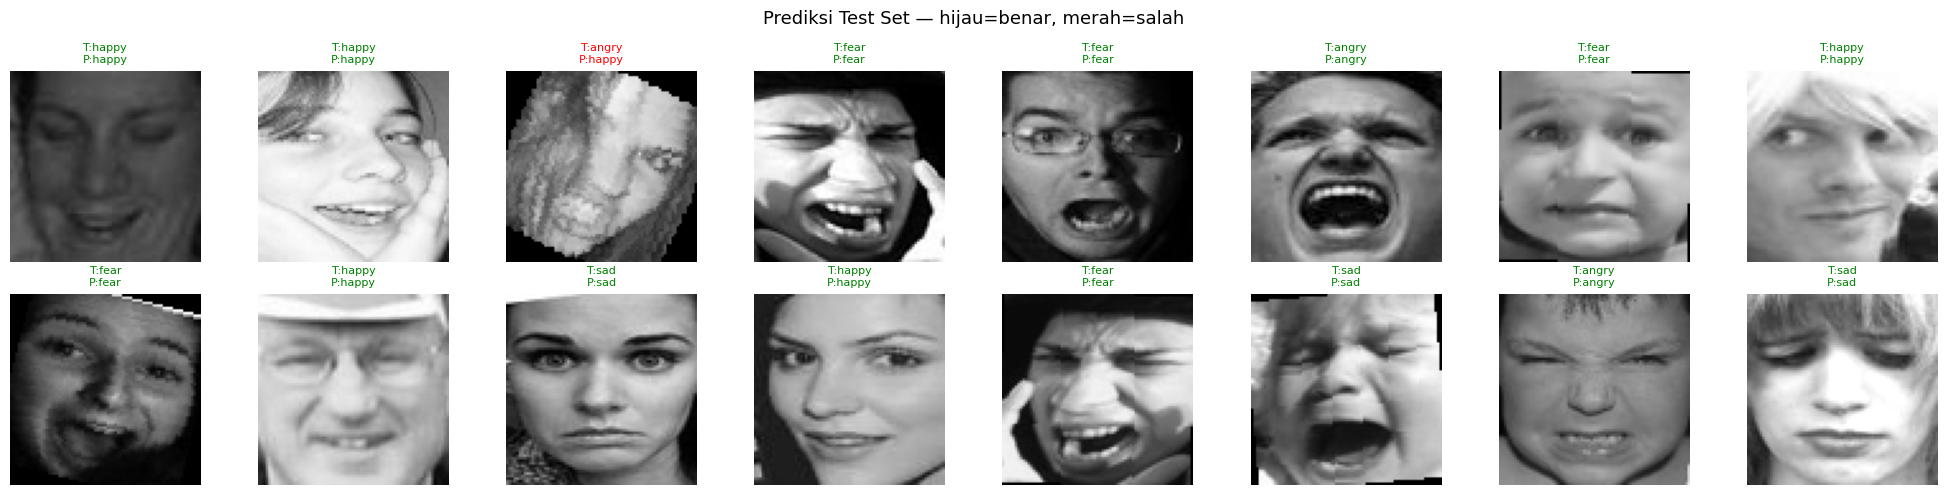


Total prediksi salah: 36 / 1000 (3.6%)


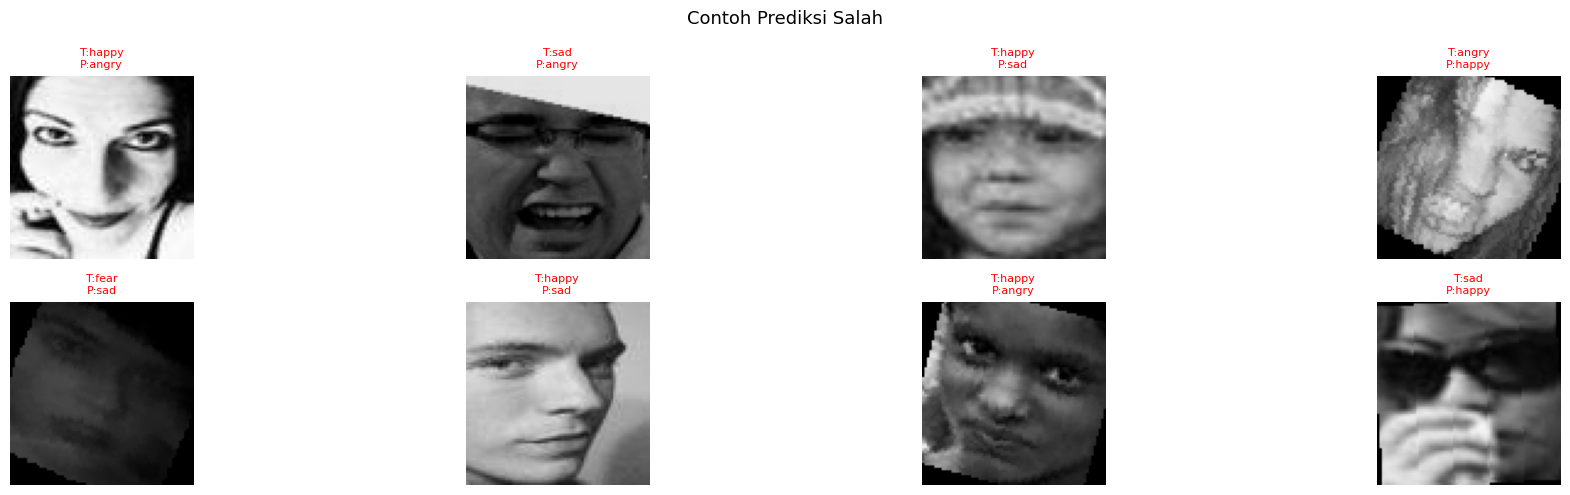

In [48]:
def show_predictions(paths, true_lbls, pred_lbls, n=16, title='Prediksi'):
    indices = random.sample(range(len(paths)), n)
    fig, axes = plt.subplots(2, n // 2, figsize=(20, 5))
    for i, ax in zip(indices, axes.flat):
        img    = Image.open(paths[i]).convert('RGB')
        ax.imshow(img)
        true_c = CLASSES[true_lbls[i]]
        pred_c = CLASSES[pred_lbls[i]]
        color  = 'green' if true_c == pred_c else 'red'
        ax.set_title(f'T:{true_c}\nP:{pred_c}', fontsize=8, color=color)
        ax.axis('off')
    plt.suptitle(title, fontsize=13)
    plt.tight_layout()
    plt.show()


show_predictions(paths_test, labels_test, tta_preds, n=16,
                 title='Prediksi Test Set — hijau=benar, merah=salah')

wrong_idx = [i for i in range(len(labels_test)) if labels_test[i] != tta_preds[i]]
print(f'\nTotal prediksi salah: {len(wrong_idx)} / {len(labels_test)} '
      f'({len(wrong_idx)/len(labels_test)*100:.1f}%)')
if len(wrong_idx) >= 8:
    wrong_paths  = [paths_test[i]  for i in wrong_idx]
    wrong_true   = [labels_test[i] for i in wrong_idx]
    wrong_pred   = [tta_preds[i]   for i in wrong_idx]
    show_predictions(wrong_paths, wrong_true, wrong_pred,
                     n=min(8, len(wrong_idx)),
                     title='Contoh Prediksi Salah')


## Cell 18 — Simpan Model Final
Menyimpan model final ke file `.keras` untuk keperluan deployment di Streamlit.

In [49]:
import shutil

best_model.save(SAVE_PATH)
print(f' Model tersimpan di: {SAVE_PATH}')

size_mb = sum(
    os.path.getsize(os.path.join(dp, f))
    for dp, dn, fns in os.walk(SAVE_PATH)
    for f in fns
) / 1e6 if os.path.isdir(SAVE_PATH) else os.path.getsize(SAVE_PATH) / 1e6
print(f'   Ukuran: {size_mb:.1f} MB')

# Salin ke Google Drive (opsional)
GDRIVE_SAVE = '/content/drive/MyDrive/emotion_efficientnet_tf.keras'
try:
    if os.path.isdir(SAVE_PATH):
        if os.path.exists(GDRIVE_SAVE):
            shutil.rmtree(GDRIVE_SAVE)
        shutil.copytree(SAVE_PATH, GDRIVE_SAVE)
    else:
        shutil.copy(SAVE_PATH, GDRIVE_SAVE)
    print(f'   Disalin ke Google Drive: {GDRIVE_SAVE}')
except Exception as e:
    print(f'   Gagal salin ke Drive (pastikan Drive ter-mount): {e}')


 Model tersimpan di: /content/emotion_efficientnet_tf.keras
   Ukuran: 18.4 MB
   Gagal salin ke Drive (pastikan Drive ter-mount): [Errno 2] No such file or directory: '/content/drive/MyDrive/emotion_efficientnet_tf.keras'


## Cell 19 — Inference Helper (Prediksi Gambar Baru)
Mendefinisikan fungsi `predict_emotion()` yang dapat digunakan untuk memprediksi emosi dari **satu gambar baru** (bukan dari dataset). Fungsi ini menerapkan pipeline CLAHE + normalisasi + TTA yang sama dengan saat testing.

In [50]:
def load_and_predict(image_path: str,
                     model_path: str = SAVE_PATH,
                     use_tta: bool   = True):
    """
    Muat model dan prediksi satu gambar.
    Return: (kelas_prediksi, confidence, dict_semua_probabilitas)
    """
    m = tf.keras.models.load_model(model_path)

    raw = Image.open(image_path).convert('RGB')
    raw_np = np.array(raw)

    lab    = cv2.cvtColor(raw_np, cv2.COLOR_RGB2Lab)
    l, a, b_chan = cv2.split(lab)
    clahe  = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
    l_eq   = clahe.apply(l)
    lab_eq = cv2.merge([l_eq, a, b_chan])
    rgb    = cv2.cvtColor(lab_eq, cv2.COLOR_Lab2RGB)

    def preprocess_single(arr):
        img = tf.image.resize(arr.astype(np.float32), [IMG_SIZE, IMG_SIZE])
        img = tf.keras.applications.efficientnet.preprocess_input(img)
        return img.numpy()[np.newaxis]

    if use_tta:
        variants = [
            rgb,
            rgb[:, ::-1, :],
            rgb,
        ]
        probs = np.zeros(NUM_CLASSES, dtype=np.float32)
        for v in variants:
            x = preprocess_single(v)
            probs += m.predict(x, verbose=0)[0]
        probs /= len(variants)
    else:
        x     = preprocess_single(rgb)
        probs = m.predict(x, verbose=0)[0]

    idx     = np.argmax(probs)
    cls_out = CLASSES[idx]
    conf    = float(probs[idx])
    prob_d  = {c: round(float(probs[i]), 4) for i, c in enumerate(CLASSES)}

    print(f'   Prediksi : {cls_out} ({conf*100:.1f}% confidence)')
    print(f'   Detail   : {prob_d}')
    return cls_out, conf, prob_d


print('   Inference helper siap.')
print('   Contoh penggunaan:')
print('   load_and_predict("/content/sample_face.jpg")')


   Inference helper siap.
   Contoh penggunaan:
   load_and_predict("/content/sample_face.jpg")


## Cell 20 — Ringkasan Akhir
Menampilkan **ringkasan keseluruhan proyek**: arsitektur model, dataset yang digunakan, hyperparameter terbaik, dan metrik performa akhir di test set.

In [51]:
print('=' * 65)
print('  RINGKASAN AKHIR — EfficientNetB0 TensorFlow/Keras')
print('=' * 65)
print(f'  Framework    : TensorFlow {tf.__version__} / Keras')
print(f'  Dataset      : RAF-DB Grayscale 75×75 → diproses {IMG_SIZE}×{IMG_SIZE}')
print(f'  Kelas        : {CLASSES}')
print(f'  Preprocessing: CLAHE + EfficientNet normalisasi')
print(f'  Split (10K)  : {len(paths_train)} train | {len(paths_val)} val | {len(paths_test)} test')
print(f'  Arsitektur   : EfficientNetB0 (pretrained ImageNet)')
print(f'  Head         : GAP → Dropout → Dense(256) → Dense({NUM_CLASSES})')
print(f'  Pipeline     : tf.data + prefetch + AUTOTUNE')
print(f'-' * 65)
print(f'  Best Val Acc    : {best_val_acc*100:.2f}%')
print(f'  Test Acc (base) : {base_acc*100:.2f}%')
print(f'  Test Acc (TTA)  : {tta_acc*100:.2f}%')
print(f'  F1 Macro (TTA)  : {f1_macro:.4f}')
print(f'  Precision (TTA) : {prec_macro:.4f}')
print(f'  Recall (TTA)    : {rec_macro:.4f}')
print(f'-' * 65)
gap = (history_all['train_acc'][-1] - history_all['val_acc'][-1]) * 100
ovr = 'Baik' if gap < 7 else 'Waspada' if gap < 15 else 'Overfitting'
print(f'  Train-Val Gap   : {gap:.2f}% → {ovr}')
tgt = 'Tercapai' if tta_acc >= 0.85 else f'Belum (butuh +{(0.85-tta_acc)*100:.1f}%)'
print(f'  Target 85%      : {tgt}')
print(f'  Model saved     : {SAVE_PATH}')
print('=' * 65)


  RINGKASAN AKHIR — EfficientNetB0 TensorFlow/Keras
  Framework    : TensorFlow 2.20.0 / Keras
  Dataset      : RAF-DB Grayscale 75×75 → diproses 224×224
  Kelas        : ['angry', 'sad', 'fear', 'happy']
  Preprocessing: CLAHE + EfficientNet normalisasi
  Split (10K)  : 8000 train | 1000 val | 1000 test
  Arsitektur   : EfficientNetB0 (pretrained ImageNet)
  Head         : GAP → Dropout → Dense(256) → Dense(4)
  Pipeline     : tf.data + prefetch + AUTOTUNE
-----------------------------------------------------------------
  Best Val Acc    : 98.10%
  Test Acc (base) : 96.00%
  Test Acc (TTA)  : 96.40%
  F1 Macro (TTA)  : 0.9639
  Precision (TTA) : 0.9641
  Recall (TTA)    : 0.9640
-----------------------------------------------------------------
  Train-Val Gap   : 1.83% → Baik
  Target 85%      : Tercapai
  Model saved     : /content/emotion_efficientnet_tf.keras


## Cell 21 — Inference dari Gambar Upload (Streamlit-ready)
Menyediakan antarmuka untuk **prediksi emosi langsung** dari gambar yang diunggah pengguna, lengkap dengan skor confidence untuk setiap kelas emosi.

Memuat model...
Model siap.

Silakan upload gambar wajah (JPG/PNG):


Saving Screenshot 2026-07-31 101911.png to Screenshot 2026-07-31 101911 (1).png


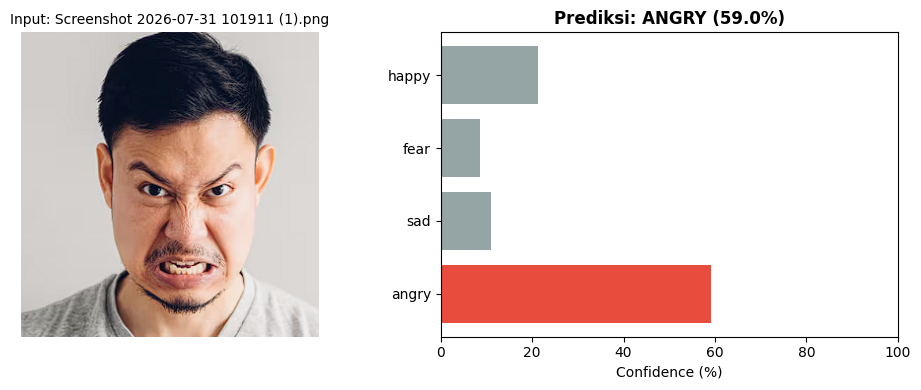

Hasil: ANGRY — Confidence: 59.0%



In [66]:
from google.colab import files
import io

CLASSES    = ['angry', 'sad', 'fear', 'happy']
IMG_SIZE   = 224
MODEL_PATH = '/content/emotion_efficientnet_tf_fix.keras'

print("Memuat model...")
model = tf.keras.models.load_model(MODEL_PATH)
print("Model siap.\n")

def preprocess_image(img_array):
    gray  = cv2.cvtColor(img_array, cv2.COLOR_RGB2GRAY)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))
    eq    = clahe.apply(gray)
    rgb   = cv2.cvtColor(eq, cv2.COLOR_GRAY2RGB)
    resized = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE)).astype(np.float32)
    normalized = tf.keras.applications.efficientnet.preprocess_input(resized)
    return normalized

def predict_with_tta(img_array, n_tta=5):
    base = preprocess_image(img_array)
    preds = []
    for _ in range(n_tta):
        aug = tf.image.random_flip_left_right(base)
        aug = tf.image.random_brightness(aug, max_delta=0.1)
        aug = tf.expand_dims(aug, 0)
        preds.append(model.predict(aug, verbose=0)[0])
    return np.mean(preds, axis=0)

print("Silakan upload gambar wajah (JPG/PNG):")
uploaded = files.upload()

for fname, fbytes in uploaded.items():
    img = Image.open(io.BytesIO(fbytes)).convert("RGB")
    img_array = np.array(img)

    probs     = predict_with_tta(img_array)
    pred_idx  = np.argmax(probs)
    pred_label = CLASSES[pred_idx]
    confidence = probs[pred_idx] * 100

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(img_array)
    axes[0].set_title(f"Input: {fname}", fontsize=10)
    axes[0].axis('off')

    colors = ['#e74c3c' if i == pred_idx else '#95a5a6' for i in range(len(CLASSES))]
    axes[1].barh(CLASSES, probs * 100, color=colors)
    axes[1].set_xlim(0, 100)
    axes[1].set_xlabel("Confidence (%)")
    axes[1].set_title(f"Prediksi: {pred_label.upper()} ({confidence:.1f}%)", fontsize=12, fontweight='bold')

    plt.tight_layout()
    plt.show()
    print(f"Hasil: {pred_label.upper()} — Confidence: {confidence:.1f}%\n")